# MIES–INFA: limpieza y comparación de clasificadores

**Objetivo:** comparar kNN con 100 vecinos, kNN con 5 vecinos, kNN ajustado por F1 macro, MLP ajustado por accuracy y MLP ajustado por F1 macro. Después seleccionaremos un umbral para mejorar el equilibrio entre clases.

Usamos únicamente los archivos que reciben los estudiantes: `X_train_Kaggle.csv`, `y_train_Kaggle.csv`, `X_test_Kaggle.csv` y la plantilla de envío. **No leemos la solución privada ni el CSV completo con etiquetas de prueba.** Todos los registros, índices y su orden se conservan; tampoco cambiamos las etiquetas.

Esta base es sintética. Limpiar errores de las variables no permite recuperar la parte aleatoria de las etiquetas. Los resultados al final muestran la mejora real y sus límites.


In [38]:
# Load the database "alertas_ninos_menores_5" and the table "alertas_ninos_menores_2anos_sintetico" into a pandas DataFrame
import pandas as pd

X_train = pd.read_csv("/Users/eugenio/Documents/ArtificialIntelligence/datasets/alertaNinosMenores24meses(Kaggle)/X_train_Kaggle.csv")
X_test = pd.read_csv("/Users/eugenio/Documents/ArtificialIntelligence/datasets/alertaNinosMenores24meses(Kaggle)/X_test_Kaggle.csv")
y_train = pd.read_csv("/Users/eugenio/Documents/ArtificialIntelligence/datasets/alertaNinosMenores24meses(Kaggle)/y_train_Kaggle.csv")
y_test = pd.read_csv("/Users/eugenio/Documents/ArtificialIntelligence/datasets/alertaNinosMenores24meses(Kaggle)/solutionsIdClassUsage.csv").drop(columns=['ID','Usage'])

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from threadpoolctl import threadpool_limits
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, TunedThresholdClassifierCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             average_precision_score, classification_report,
                             ConfusionMatrixDisplay, PrecisionRecallDisplay)

SEED = 42
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'datasets').is_dir())
data_dir = root / 'datasets/alertaNinosMenores24meses(Kaggle)'
out_dir = root / 'resources/challenges/mies_infa_results'
out_dir.mkdir(exist_ok=True)
X = pd.read_csv(data_dir / 'X_train_Kaggle.csv')
y_frame = pd.read_csv(data_dir / 'y_train_Kaggle.csv')
y = y_frame['alerta_desnutricion']
X_kaggle = pd.read_csv(data_dir / 'X_test_Kaggle.csv')
submission_template = pd.read_csv(data_dir / 'sample_submission_malnutrition.csv')
assert len(X) == len(y) and X.index.equals(y.index)
assert X.columns.equals(X_kaggle.columns)
assert len(X_kaggle) == len(submission_template)
assert set(y.unique()) == {0, 1}
print(f'Entrenamiento etiquetado: {len(X):,}; prueba Kaggle sin etiquetas: {len(X_kaggle):,}')
display(y.value_counts().rename('Registros').to_frame().assign(Proporcion=y.value_counts(normalize=True)))


Entrenamiento etiquetado: 70,000; prueba Kaggle sin etiquetas: 30,000


,Registros,Proporcion
alerta_desnutricion,,
0,62991,0.899871
1,7009,0.100129


## 1. Qué significa cada columna y qué se limpia

| Columna | Significado | Tratamiento |
|---|---|---|
| `edad_meses` | Edad en meses | Negativos y valores >24 se marcan como faltantes. Admitimos 24 por la convención de esta base. Conservamos indicadores separados de edad negativa y fuera de rango. |
| `peso_kg` | Peso en kg | Valores ≤0 o ≥30 se marcan como faltantes. El bloque aislado 30–60 corresponde a la contaminación de este dataset sintético; no es un umbral clínico universal. |
| `talla_cm` | Talla en cm | Valores ≤0 serían inválidos. Conservamos las tallas positivas observadas, incluyendo las bajas. |
| `sexo` | Categoría M/F | Normalización de texto y one-hot. |
| `region` | Costa, Sierra, Amazonía, Insular | Normalización de texto y one-hot, sin imponer orden. |
| `nivel_educacion_madre` | Nivel educativo | Normalización de texto y one-hot. |
| `alerta_desnutricion` | Objetivo binario | Se conserva sin cambios; nunca entra al preprocesamiento de X. |

**No se borran filas, duplicados ni índices.** Un valor sospechoso se convierte en `NaN`; cada pipeline aprende cómo imputarlo usando solo su entrenamiento. No aplicamos una eliminación genérica por IQR: un peso o talla bajos pueden ser la señal que se quiere detectar. Tampoco normalizamos las categorías usando estadísticas del test.


,Faltantes originales,Valores invalidados,Faltantes tras limpieza
edad_meses,0,7084,7084
sexo,0,0,0
region,0,0,0
nivel_educacion_madre,0,0,0
peso_kg,3469,684,4153
talla_cm,7049,0,7049


,edad_meses,peso_kg,talla_cm
count,70000.00,66531.00,62951.00
mean,11.46,6.88,67.48
std,8.25,4.65,11.94
min,-12.00,-0.81,34.90
25%,5.00,4.50,57.44
50%,11.00,6.52,67.38
75%,18.00,8.55,77.44
max,29.00,59.98,98.21


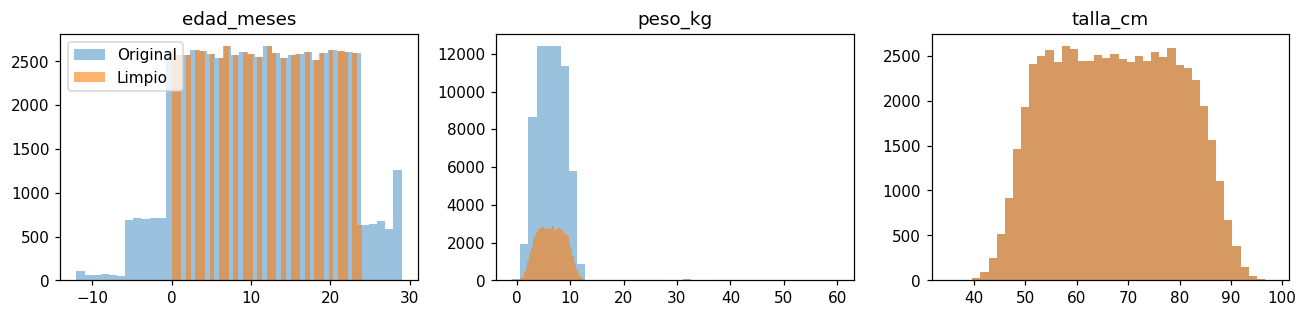

In [2]:
NUMERIC = ['edad_meses', 'peso_kg', 'talla_cm']
CATEGORIES = {
    'sexo': ['M', 'F'],
    'region': ['Costa', 'Sierra', 'Amazonía', 'Insular'],
    'nivel_educacion_madre': ['Sin escolaridad', 'Primaria', 'Secundaria', 'Superior']
}

def clean_data(data):
    z = data.copy()
    z[NUMERIC] = z[NUMERIC].apply(pd.to_numeric, errors='coerce').replace([np.inf, -np.inf], np.nan)
    z['edad_negativa'] = (z.edad_meses < 0).astype(int)
    z['edad_fuera_rango'] = ((z.edad_meses < 0) | (z.edad_meses > 24)).astype(int)
    z['peso_invalido'] = ((z.peso_kg <= 0) | (z.peso_kg >= 30)).astype(int)
    z.loc[z.edad_meses.lt(0) | z.edad_meses.gt(24), 'edad_meses'] = np.nan
    z.loc[z.peso_kg.le(0) | z.peso_kg.ge(30), 'peso_kg'] = np.nan
    z.loc[z.talla_cm.le(0), 'talla_cm'] = np.nan
    for column, allowed in CATEGORIES.items():
        text = z[column].astype('string').str.strip().str.casefold()
        z[column] = text.map({value.casefold(): value for value in allowed})
    assert len(z) == len(data) and z.index.equals(data.index)
    return z

X_clean = clean_data(X)
audit = pd.DataFrame({
    'Faltantes originales': X.isna().sum(),
    'Valores invalidados': (X.notna() & X_clean[X.columns].isna()).sum(),
    'Faltantes tras limpieza': X_clean[X.columns].isna().sum()
})
display(audit)
display(X[NUMERIC].describe().round(2))
audit.to_csv(out_dir / 'auditoria_limpieza.csv')
fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for ax, column in zip(axes, NUMERIC):
    ax.hist(X[column].dropna(), bins=40, alpha=0.45, label='Original')
    ax.hist(X_clean[column].dropna(), bins=40, alpha=0.6, label='Limpio')
    ax.set_title(column)
axes[0].legend()
plt.tight_layout()
plt.show()


## 2. Reservar datos sin tocar las respuestas de Kaggle

Dividimos el entrenamiento público en **60% ajuste, 20% selección del umbral y 20% evaluación local final**, con estratificación. Las búsquedas usan 3 particiones internas únicamente sobre el primer 60%. Los cinco experimentos comparten las particiones.

La imputación, el escalado y la codificación se ajustan dentro de cada pipeline y cada partición. La limpieza anterior usa reglas fijas y no aprendió medias ni usó etiquetas. La evaluación local final se mostrará después de elegir modelo y umbral.


In [3]:
X_dev, X_holdout, y_dev, y_holdout = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED)
X_fit, X_threshold, y_fit, y_threshold = train_test_split(
    X_dev, y_dev, test_size=0.25, stratify=y_dev, random_state=SEED)
assert set(X_fit.index).isdisjoint(X_threshold.index)
assert set(X_dev.index).isdisjoint(X_holdout.index)
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)

numeric_clean = NUMERIC + ['edad_negativa', 'edad_fuera_rango', 'peso_invalido']

def model_pipeline(model, clean=True):
    preprocessing = ColumnTransformer([
        ('numeric', make_pipeline(SimpleImputer(strategy='median', add_indicator=True),
                                  StandardScaler()), numeric_clean if clean else NUMERIC),
        ('categorical', make_pipeline(SimpleImputer(strategy='most_frequent'),
                                      OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
         list(CATEGORIES))
    ])
    return Pipeline([
        ('clean', FunctionTransformer(clean_data) if clean else 'passthrough'),
        ('preprocess', preprocessing),
        ('model', model)
    ])

warning_log = []

def quiet_call(action, *args):
    # Capture repeated warnings once per call; retain a diagnostic summary.
    with warnings.catch_warnings(record=True) as captured, threadpool_limits(limits=1):
        warnings.simplefilter('always', ConvergenceWarning)
        warnings.simplefilter('once', RuntimeWarning)
        result = action(*args)
    for warning in captured:
        if issubclass(warning.category, (ConvergenceWarning, RuntimeWarning)):
            warning_log.append({'Tipo': warning.category.__name__, 'Mensaje': str(warning.message)})
        else:
            warnings.warn(warning.message, warning.category)
    return result

def fit_quiet(estimator, features, target):
    quiet_call(estimator.fit, features, target)
    if hasattr(estimator, 'cv_results_'):
        for key, values in estimator.cv_results_.items():
            if key.startswith('mean_test'):
                assert np.isfinite(values).all(), 'La búsqueda produjo métricas no finitas.'
    if isinstance(estimator, Pipeline) and isinstance(estimator['model'], MLPClassifier):
        assert all(np.isfinite(w).all() for w in estimator['model'].coefs_)
    return estimator

def positive_probability(model, features):
    probabilities = quiet_call(model.predict_proba, features)
    assert np.isfinite(probabilities).all(), 'Probabilidades no finitas: revisar avisos numéricos.'
    assert ((probabilities >= 0) & (probabilities <= 1)).all()
    np.testing.assert_allclose(probabilities.sum(axis=1), 1, atol=1e-6)
    return probabilities[:, 1]

print(f'Ajuste: {len(X_fit):,}; umbral: {len(X_threshold):,}; evaluación local: {len(X_holdout):,}')


Ajuste: 42,000; umbral: 14,000; evaluación local: 14,000


## 3. kNN con 100 y 5 vecinos

Ambos usan el mismo preprocesamiento. Un k grande puede favorecer la mayoría; uno pequeño puede producir positivos y también aprender ruido. Añadimos un kNN de 5 vecinos sin invalidar anomalías como control para medir si la limpieza aporta algo; aun ese control debe imputar y escalar para poder entrenar.


In [4]:
models = {}
for k in [100, 5]:
    models[f'kNN k={k}'] = fit_quiet(
        model_pipeline(KNeighborsClassifier(n_neighbors=k, n_jobs=1)), X_fit, y_fit)
raw_knn = fit_quiet(model_pipeline(KNeighborsClassifier(n_neighbors=5, n_jobs=1), clean=False),
                    X_fit, y_fit)
print('kNN de 100 y 5 vecinos entrenados.')


kNN de 100 y 5 vecinos entrenados.


## 4. kNN: búsqueda maximizando F1 macro

F1 macro promedia el F1 de las dos clases con el mismo peso. La búsqueda cambia el número de vecinos y cómo votan. No garantiza un F1 alto si falta señal predictiva.


In [5]:
knn_search = GridSearchCV(
    model_pipeline(KNeighborsClassifier(n_jobs=1)),
    {'model__n_neighbors': [5, 15, 35, 100], 'model__weights': ['uniform', 'distance']},
    scoring='f1_macro', cv=cv, n_jobs=1, verbose=0, error_score='raise')
fit_quiet(knn_search, X_fit, y_fit)
models['kNN búsqueda F1 macro'] = knn_search.best_estimator_
print('Mejores parámetros kNN:', knn_search.best_params_)
print(f'F1 macro CV: {knn_search.best_score_:.3f}')


Mejores parámetros kNN: {'model__n_neighbors': 5, 'model__weights': 'distance'}
F1 macro CV: 0.503


## 5. MLP: búsqueda por accuracy y por F1 macro

Una búsqueda calcula ambas métricas para los mismos candidatos y particiones; seleccionamos y reentrenamos por separado el ganador de **accuracy** y el de **F1 macro**. Esto equivale a dos búsquedas con idéntica rejilla sin duplicar todos los entrenamientos. Los ganadores pueden coincidir.

`scoring` selecciona hiperparámetros; no cambia la función de pérdida con la que aprende la red. Usamos `early_stopping=False`: la parada temprana incorporada al MLP controla accuracy, aunque GridSearchCV evalúe F1 macro. El entrenamiento se detiene por la pérdida o el límite de iteraciones. No se imprimen iteraciones; los avisos de convergencia se resumen una sola vez.


In [6]:
mlp = MLPClassifier(max_iter=250, batch_size=512, learning_rate_init=0.001,
                    early_stopping=False, n_iter_no_change=15, tol=1e-4,
                    random_state=SEED, verbose=False)
mlp_search = GridSearchCV(
    model_pipeline(mlp),
    {'model__hidden_layer_sizes': [(16,), (32, 16)], 'model__alpha': [0.001, 0.1]},
    scoring={'accuracy': 'accuracy', 'f1_macro': 'f1_macro'},
    refit=False, cv=cv, n_jobs=1, verbose=0, error_score='raise')
fit_quiet(mlp_search, X_fit, y_fit)
mlp_cv = pd.DataFrame(mlp_search.cv_results_)
display(mlp_cv[['params', 'mean_test_accuracy', 'mean_test_f1_macro']].round(4))
for score, name in [('accuracy', 'MLP búsqueda accuracy'), ('f1_macro', 'MLP búsqueda F1 macro')]:
    best = mlp_cv.loc[mlp_cv[f'mean_test_{score}'].idxmax(), 'params']
    models[name] = fit_quiet(clone(mlp_search.estimator).set_params(**best), X_fit, y_fit)
    print(name, best)


MLP búsqueda accuracy {'model__alpha': 0.001, 'model__hidden_layer_sizes': (16,)}
MLP búsqueda F1 macro {'model__alpha': 0.001, 'model__hidden_layer_sizes': (16,)}


,params,mean_test_accuracy,mean_test_f1_macro
0,"{'model__alpha': 0.001, 'model__hidden_layer_sizes': (16,)}",0.8999,0.4737
1,"{'model__alpha': 0.001, 'model__hidden_layer_sizes': (32, 16)}",0.8999,0.4736
2,"{'model__alpha': 0.1, 'model__hidden_layer_sizes': (16,)}",0.8999,0.4737
3,"{'model__alpha': 0.1, 'model__hidden_layer_sizes': (32, 16)}",0.8999,0.4737


## 6. Dejar de predecir todo como 0: elegir el umbral en validación

En estos clasificadores, la decisión habitual usa aproximadamente 0.5, pero puede que ninguna probabilidad alcance ese valor. Comparamos **los mismos modelos** en una rejilla de umbrales y elegimos el mayor F1 macro en el conjunto reservado para este paso. Nunca elegimos con la evaluación local ni con las respuestas de Kaggle.

Bajar el umbral puede aumentar recall y falsas alarmas. Si las probabilidades no discriminan, el umbral no inventa información. Usar F1 macro tampoco obliga a obtener el mismo F1 para cada clase.


In [7]:
threshold_grid = np.linspace(0.02, 0.50, 97)
selection_rows = []
for name, model in models.items():
    probabilities = positive_probability(model, X_threshold)
    scores = [f1_score(y_threshold, probabilities >= t, average='macro', zero_division=0)
              for t in threshold_grid]
    best_index = int(np.argmax(scores))
    selection_rows.append({'Modelo': name, 'Umbral': threshold_grid[best_index],
                           'F1 macro validación': scores[best_index],
                           'F1 macro sin ajuste': f1_score(y_threshold, (probabilities > 0.5).astype(int),
                                                          average='macro', zero_division=0)})
selection = pd.DataFrame(selection_rows).sort_values('F1 macro validación', ascending=False)
display(selection.round(4))
selected_name = selection.iloc[0]['Modelo']
selected_threshold = float(selection.iloc[0]['Umbral'])
selected_model = models[selected_name]
print(f'Selección congelada: {selected_name}; umbral = {selected_threshold:.3f}')
selection.to_csv(out_dir / 'seleccion_validacion.csv', index=False)


Selección congelada: kNN búsqueda F1 macro; umbral = 0.290


,Modelo,Umbral,F1 macro validación,F1 macro sin ajuste
2,kNN búsqueda F1 macro,0.290,0.5257,0.4987
0,kNN k=100,0.165,0.5257,0.4736
1,kNN k=5,0.205,0.5225,0.4906
3,MLP búsqueda accuracy,0.165,0.5207,0.4736
4,MLP búsqueda F1 macro,0.165,0.5207,0.4736


## 7. Evaluación local final: las dos clases y el costo de detectar positivos

Abrimos el conjunto local reservado una sola vez para la comparación. La tabla incluye los cinco experimentos pedidos, la referencia “siempre 0”, el control sin limpieza y el modelo ya elegido con su umbral. **No cambiamos la selección después de ver esta tabla.**

F1 macro y el F1 de cada clase muestran el compromiso. Recall 1 mide cuántas alertas se encuentran; precisión 1, cuántas de las emitidas son correctas. AP mide el ranking de probabilidades y se compara con la prevalencia (~10%). Cambiar el umbral no cambia AP.


Informe del modelo seleccionado (kNN búsqueda F1 macro, umbral 0.290):
              precision    recall  f1-score   support

           0      0.904     0.885     0.894     12598
           1      0.128     0.153     0.139      1402

    accuracy                          0.811     14000
   macro avg      0.516     0.519     0.517     14000
weighted avg      0.826     0.811     0.818     14000



,Accuracy,F1 macro,F1 clase 0,F1 clase 1,Recall 1,Precision 1,AP,Predicciones 1
Modelo,,,,,,,,
Siempre 0,0.8999,0.4736,0.9473,0.0000,0.0000,0.0000,0.1001,0
kNN k=5 sin limpiar,0.8884,0.4871,0.9408,0.0334,0.0193,0.1262,0.1144,214
kNN k=100,0.8999,0.4736,0.9473,0.0000,0.0000,0.0000,0.1341,0
kNN k=5,0.8892,0.4850,0.9413,0.0288,0.0164,0.1179,0.1139,195
kNN búsqueda F1 macro,0.8761,0.4972,0.9337,0.0607,0.0399,0.1261,0.1144,444
MLP búsqueda accuracy,0.8999,0.4736,0.9473,0.0000,0.0000,0.0000,0.1433,0
MLP búsqueda F1 macro,0.8999,0.4736,0.9473,0.0000,0.0000,0.0000,0.1433,0
Seleccionado + umbral,0.8114,0.5168,0.8941,0.1395,0.1526,0.1284,0.1144,1667


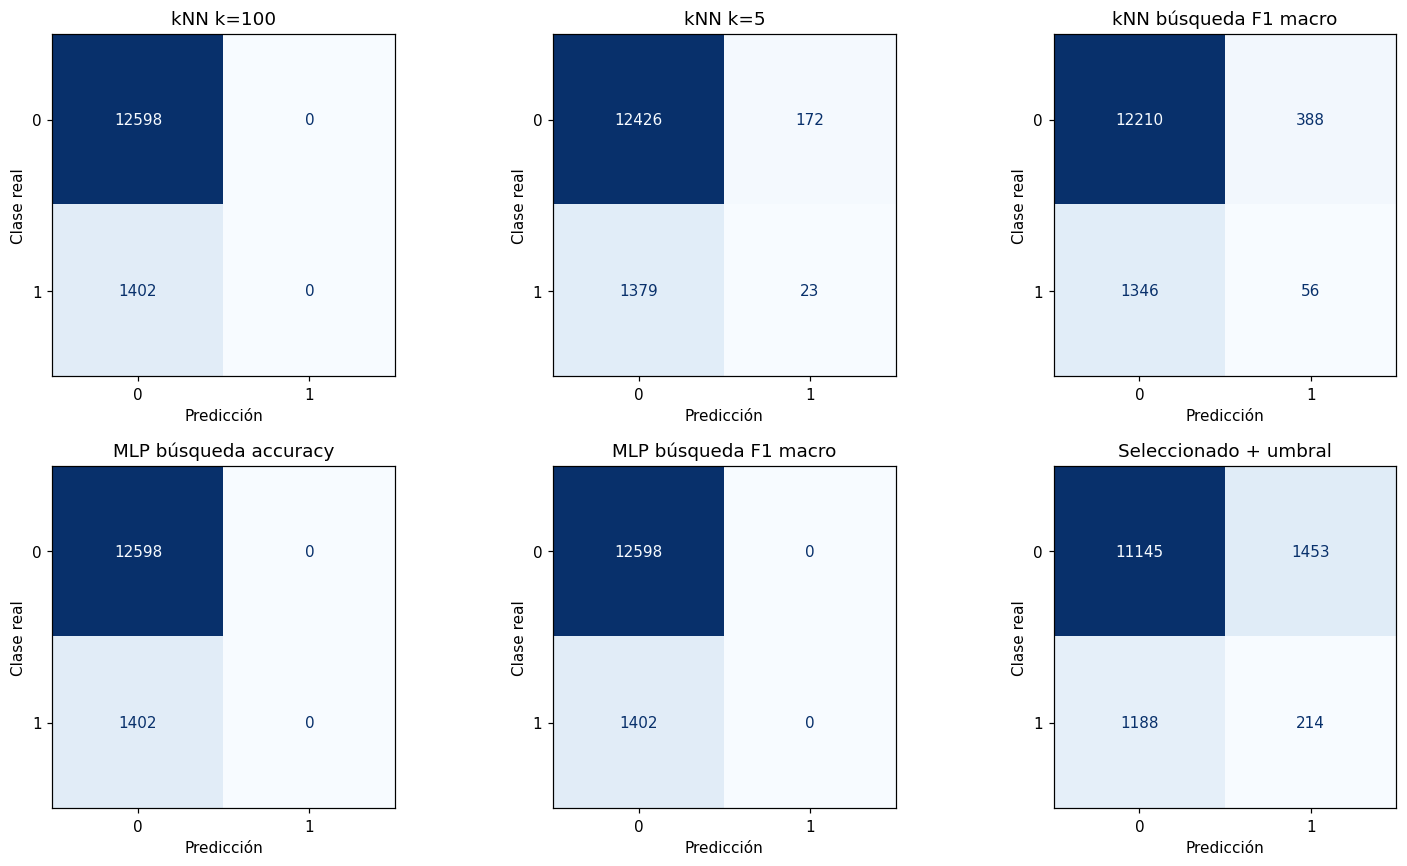

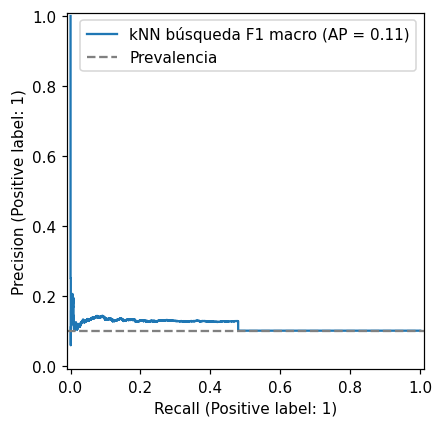

In [8]:
predictions = {'Siempre 0': np.zeros(len(y_holdout), dtype=int)}
probabilities = {'Siempre 0': np.full(len(y_holdout), y_fit.mean())}
for name, model in {'kNN k=5 sin limpiar': raw_knn, **models}.items():
    probabilities[name] = positive_probability(model, X_holdout)
    predictions[name] = (probabilities[name] > 0.5).astype(int)
final_name = 'Seleccionado + umbral'
probabilities[final_name] = probabilities[selected_name]
predictions[final_name] = (probabilities[final_name] >= selected_threshold).astype(int)
rows = []
for name, pred in predictions.items():
    class_f1 = f1_score(y_holdout, pred, labels=[0, 1], average=None, zero_division=0)
    rows.append({'Modelo': name, 'Accuracy': accuracy_score(y_holdout, pred),
                 'F1 macro': class_f1.mean(), 'F1 clase 0': class_f1[0], 'F1 clase 1': class_f1[1],
                 'Recall 1': recall_score(y_holdout, pred, zero_division=0),
                 'Precision 1': precision_score(y_holdout, pred, zero_division=0),
                 'AP': average_precision_score(y_holdout, probabilities[name]),
                 'Predicciones 1': int(pred.sum())})
comparison = pd.DataFrame(rows).set_index('Modelo')
display(comparison.round(4))
comparison.to_csv(out_dir / 'comparacion_holdout.csv')
print(f'Informe del modelo seleccionado ({selected_name}, umbral {selected_threshold:.3f}):')
print(classification_report(y_holdout, predictions[final_name], digits=3, zero_division=0))

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, name in zip(axes.flat, [*models, final_name]):
    ConfusionMatrixDisplay.from_predictions(y_holdout, predictions[name], labels=[0, 1],
                                           ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(name)
    ax.set_xlabel('Predicción')
    ax.set_ylabel('Clase real')
plt.tight_layout()
plt.savefig(out_dir / 'matrices_confusion.png', dpi=140)
plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
PrecisionRecallDisplay.from_predictions(y_holdout, probabilities[final_name], ax=ax,
                                       name=selected_name)
ax.axhline(y_holdout.mean(), linestyle='--', color='gray', label='Prevalencia')
ax.legend()
plt.tight_layout()
plt.savefig(out_dir / 'precision_recall.png', dpi=140)
plt.show()


## 8. Qué se puede concluir y qué no

- Compara `kNN k=5 sin limpiar` y `kNN k=5` para medir el efecto de las reglas de limpieza con el mismo split. No se presupone que toda limpieza mejore la métrica.
- Compara los cinco experimentos con su decisión habitual antes de atribuir una mejora a la arquitectura. Es posible que los dos MLP seleccionen lo mismo.
- El modelo con umbral ajustado puede dejar de predecir solo la mayoría, pero hay que revisar las falsas alarmas y AP. Un pequeño aumento de F1 macro no equivale a predecir bien las alertas.
- El notebook generador asigna la etiqueta usando una sigmoide con un término aleatorio normal y un corte en el percentil 90. Los estudiantes no observan ese término. Además, los coeficientes negativos de ciertos factores reducen la probabilidad de alerta, aunque los comentarios indiquen lo contrario. No modificamos esas etiquetas: forman parte de esta competencia.
- No se reconstruye la semilla ni se usa el archivo completo para recuperar respuestas. Para mejorar, se pueden estudiar nuevas variables y parámetros **dentro de validación**, sin prometer que la limpieza elimine ruido del objetivo.

Referencias técnicas: [pipelines y prevención de fuga](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage), [MLPClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPClassifier.html), [ajuste de umbral](https://scikit-learn.org/stable/modules/classification_threshold.html).

**Avisos numéricos:** se guardan resumidos al final en lugar de repetirse durante la búsqueda. Los avisos de convergencia indican un límite de entrenamiento; ocultar sus repeticiones no los resuelve. En algunos Mac, NumPy emite avisos de `matmul` aun con resultados correctos ([incidencia oficial](https://github.com/numpy/numpy/issues/28687)). Comprobamos resultados finitos; si aparece un error de esas comprobaciones, se detiene la ejecución.


## 9. Ajuste final y archivo para Kaggle

Tras terminar la evaluación, reutilizamos todo el entrenamiento público. Conservamos la arquitectura e hiperparámetros elegidos y recalibramos el umbral por validación cruzada para el ajuste final. Las antiguas filas de evaluación local ahora son entrenamiento: no volvemos a informar una métrica sobre ellas.

El pipeline sigue conservando todas las filas. La plantilla proporciona los IDs en el mismo orden que X_test. Exportamos copias limpiadas con `NaN` e indicadores, **sin imputarlas globalmente**; las estadísticas de imputación pertenecen a cada pipeline. Los CSV originales quedan intactos. El archivo de envío se crea localmente y no se sube a Kaggle.


In [9]:
final_model = TunedThresholdClassifierCV(
    clone(selected_model), scoring='f1_macro', thresholds=threshold_grid,
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED), n_jobs=1)
fit_quiet(final_model, X, y)
submission = submission_template.copy()
submission['alerta_desnutricion'] = quiet_call(final_model.predict, X_kaggle).astype(int)
assert len(submission) == len(X_kaggle)
assert submission['ID'].equals(submission_template['ID'])
assert submission['ID'].is_unique and set(submission['alerta_desnutricion'].unique()) <= {0, 1}
submission.to_csv(out_dir / 'submission_mies_f1macro.csv', index=False)
clean_data(X).to_csv(out_dir / 'X_train_clean_flags.csv', index=False)
clean_data(X_kaggle).to_csv(out_dir / 'X_test_clean_flags.csv', index=False)
y_frame.to_csv(out_dir / 'y_train_sin_cambios.csv', index=False)
print(f'Umbral final por CV: {final_model.best_threshold_:.3f}')
print(f'Envío: {len(submission):,} filas, {submission.alerta_desnutricion.sum():,} predicciones de clase 1.')
print(out_dir / 'submission_mies_f1macro.csv')

if warning_log:
    warning_summary = pd.DataFrame(warning_log).value_counts().rename('Veces registradas').reset_index()
    display(warning_summary)
    warning_summary.to_csv(out_dir / 'avisos_resumidos.csv', index=False)
    print('Avisos resumidos; las métricas, pesos del MLP y probabilidades fueron comprobados como finitos.')


Umbral final por CV: 0.275
Envío: 30,000 filas, 3,935 predicciones de clase 1.
/Users/eugenio/Documents/ArtificialIntelligence/resources/challenges/mies_infa_results/submission_mies_f1macro.csv
Avisos resumidos; las métricas, pesos del MLP y probabilidades fueron comprobados como finitos.


,Tipo,Mensaje,Veces registradas
0,RuntimeWarning,divide by zero encountered in matmul,30
1,RuntimeWarning,invalid value encountered in matmul,30
2,RuntimeWarning,overflow encountered in matmul,30
